In [1]:
import myhda_ur as hda

In [2]:
hdata = hda.load_scifate()

### Expression-distance clusters

gene x cell expression matrix -> distance matrix -> cluster -> visualize with PCA

In [3]:
# Get top 1000 HVGs
genes_2000 = hdata.get_highly_variable_genes(n=2000)

# Get 100 random cells for each timepoint
cells_600 = hdata.get_timepoint_cells(n=100)   # 100 x 6 time points

# Initialize a temporary subset object for the selected cells 
subset_cells_ = hdata[genes_2000, cells_600]  # 2000 genes x 600 cells

In [9]:
# Compute cell-cell similarity of the selected cells using normalized gene expression values 
hdata.compute_similarity(
    data=subset_cells_,
    key="X",
    kind="cell",
    method="correlation"
)
sim_cells_ = hdata.similarities["correlation_X_cell"]

Similarity "correlation_X_cell" stored! 



In [17]:
# Cluster the cells using Spectral Clustering
hdata.cluster_spectral(
        sim = sim_cells_,                                 
        kind = "cell",
        k = 6
    )
cl_spec_cells_ = hdata.clusters["spectral_k6_cell"]

Cluster "spectral_k6_cell" stored! 



In [18]:
# Reduce the dimensions into 2D using PCA 
hdata.reduce_PCA(
    data = subset_cells_,
    key = "X",
    kind = "cell"
)
em_pca_cells_ = hdata.embeddings["pca_cell"]

PCA embedding "pca_cell" stored! 



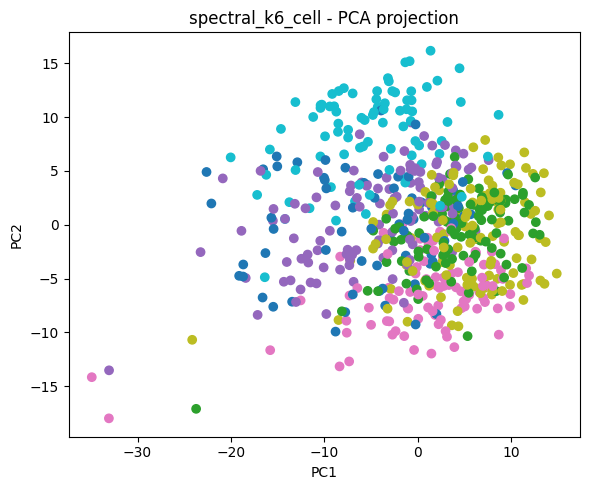

In [19]:
# Visualize the KMeans clusters as a scatter plot under PCA
hda.visualize.scatter(
    cluster=cl_spec_cells_,
    embedding=em_pca_cells_,
    reduction="PCA",
    show_label=False
)

### PCA-based clusters 

gene x cell expression matrix -> PCA (cell x PC) -> distance matrix -> cluster

In [4]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_cells_,
    key="X",
    kind="cell",
    n_pc=20
)

pc_matrix = hdata.layers["pca"]     # shape (600, 20)

PCA matrix X x 20 PCs stored in data.layers["pca"] 

PCA embedding "pca_cell_PC20" stored! 



In [11]:
# Compute cell-cell distance matrix in PC space
hdata.compute_similarity(
    data=subset_cells_,
    key="pca",
    method="correlation"
)

sim_pca_cells_ = hdata.similarities["correlation_pca_cell"]   # shape (600, 600)

Similarity "correlation_pca_cell" stored! 



In [8]:
# Cluster in PC space
hdata.cluster_spectral(
    sim=sim_pca_cells_,
    kind="cell",
    k=6
)

cl_pca_cells_ = hdata.clusters["spectral_k6_cell"]

Cluster "spectral_k6_cell" stored! 



In [9]:
# Reuse the embeddings already stored by compute_PCA
em_pca_cells_ = hdata.embeddings['pca_cell_PC20']  

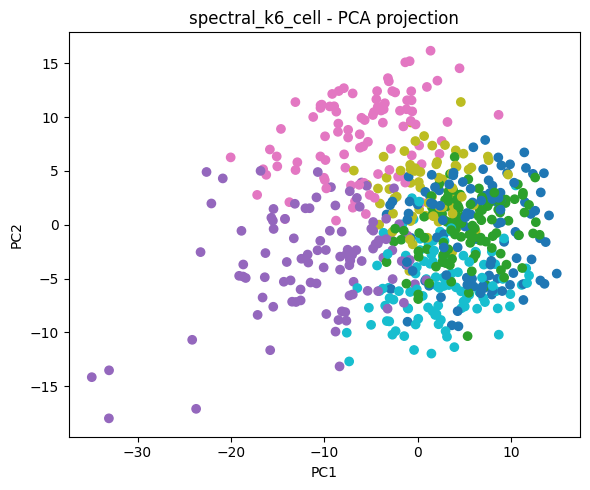

In [10]:
# Visualize 
hda.visualize.scatter(
    cluster=cl_pca_cells_,
    embedding=em_pca_cells_,
    reduction="PCA",
    show_label=False
)